# Model Training 3 - Multilayer Perceptron (MLP)
### 1. 

In [31]:
# imports
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
# train and test data
train_df = pd.read_csv("../Data/TrainPreprocessed.csv")
test_df = pd.read_csv("../Data/TestPreprocessed.csv")

X_train = train_df.drop(columns=["LIFETIME"])
y_train = train_df["LIFETIME"]

X_test = test_df.drop(columns=["LIFETIME"])
y_test = test_df["LIFETIME"]


In [33]:
# function to plot model evaluation
sns.set_theme(style="whitegrid")

def plot_model_evaluation(y_true, y_pred, title="Model Evaluation"):
    """
    Plot residual, prediction, and ground truth diagnostics for regression models.
    
    Parameters:
        y_true (array-like): Ground truth values
        y_pred (array-like): Model predictions
        title (str): Title of the overall plot
    """
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()
    residuals = y_pred - y_true

    # Create figure layout
    fig, axs = plt.subplots(3, 2, figsize=(14, 14))
    fig.suptitle(title, fontsize=16)

    # 1. Residual Histogram
    sns.histplot(residuals, bins=60, ax=axs[0, 0], color="C0")
    axs[0, 0].set_title("Residual Histogram")
    axs[0, 0].set_xlabel("Residual")
    axs[0, 0].set_ylabel("Density")

    # 2. Ground Truth Histogram
    sns.histplot(y_true, bins=60, ax=axs[0, 1], color="C0")
    axs[0, 1].set_title("Ground Truth Histogram")
    axs[0, 1].set_xlabel("Ground truth")
    axs[0, 1].set_ylabel("Density")

    # 3. Prediction Histogram
    sns.histplot(y_pred, bins=60, ax=axs[1, 0], color="C0")
    axs[1, 0].set_title("Prediction Histogram")
    axs[1, 0].set_xlabel("Prediction")
    axs[1, 0].set_ylabel("Density")

    # 4. Ground Truth vs Predictions (binned)
    df_gt_pred = pd.DataFrame({"ground_truth": y_true, "prediction": y_pred})
    df_gt_pred["gt_bin"] = pd.cut(df_gt_pred["ground_truth"], bins=30)
    binned_gt = df_gt_pred.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["prediction"], label="Prediction", color="darkorange")
    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["ground_truth"], linestyle="--", color="C0", label="Ideal")
    axs[1, 1].set_title("Ground Truth vs Predictions (Binned)")
    axs[1, 1].set_xlabel("Ground Truth")
    axs[1, 1].set_ylabel("Prediction")
    axs[1, 1].legend()

    # 5. Predictions vs Residual (binned)
    df_pred_res = pd.DataFrame({"prediction": y_pred, "residual": residuals})
    df_pred_res["pred_bin"] = pd.cut(df_pred_res["prediction"], bins=30)
    binned_pred = df_pred_res.groupby("pred_bin", observed=False).mean(numeric_only=True)

    axs[2, 0].plot(binned_pred["prediction"], binned_pred["residual"], color="darkorange")
    axs[2, 0].axhline(0, linestyle="--", color="C0")
    axs[2, 0].set_title("Predictions vs Residual (Binned)")
    axs[2, 0].set_xlabel("Prediction")
    axs[2, 0].set_ylabel("Residual")

    # 6. Ground Truth vs Residual (binned)
    df_gt_res = pd.DataFrame({"ground_truth": y_true, "residual": residuals})
    df_gt_res["gt_bin"] = pd.cut(df_gt_res["ground_truth"], bins=30)
    binned_gt_res = df_gt_res.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[2, 1].plot(binned_gt_res["ground_truth"], binned_gt_res["residual"], color="darkorange")
    axs[2, 1].axhline(0, linestyle="--", color="C0")
    axs[2, 1].set_title("Ground Truth vs Residual (Binned)")
    axs[2, 1].set_xlabel("Ground Truth")
    axs[2, 1].set_ylabel("Residual")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


In [34]:
# define model architecture
model1 = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="relu")  # ensure output is non-negative
])

In [35]:
# compile model
model1.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [36]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model1.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
490/490 ━━━━━━━━━━━━━━━━━━━━ 1s 822us/step - loss: 30699268.0000 - root_mean_squared_error: 5524.3174 - val_loss: 4932945.5000 - val_root_mean_squared_error: 2221.0234
Epoch 2/100
490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 685us/step - loss: 4409745.0000 - root_mean_squared_error: 2091.9553 - val_loss: 1533347.7500 - val_root_mean_squared_error: 1238.2842
Epoch 3/100
490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 677us/step - loss: 1770317.7500 - root_mean_squared_error: 1329.7788 - val_loss: 1069588.2500 - val_root_mean_squared_error: 1034.2090
Epoch 4/100
490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 674us/step - loss: 1311724.8750 - root_mean_squared_error: 1144.7732 - val_loss: 983500.6250 - val_root_mean_squared_error: 991.7160
Epoch 5/100
490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 687us/step - loss: 1342459.7500 - root_mean_squared_error: 1158.0743 - val_loss: 927658.9375 - val_root_mean_squared_error: 963.1505
Epoch 6/100
490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 839us/step - loss: 1511035.2500 - root_mean_squared_error: 1223.

In [37]:
# evaluate model
loss, rmse = model1.evaluate(X_test, y_test)
print("Test RMSE:", rmse)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 469us/step - loss: 751295.0000 - root_mean_squared_error: 864.7521
Test RMSE: 861.4373779296875


153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 436us/step


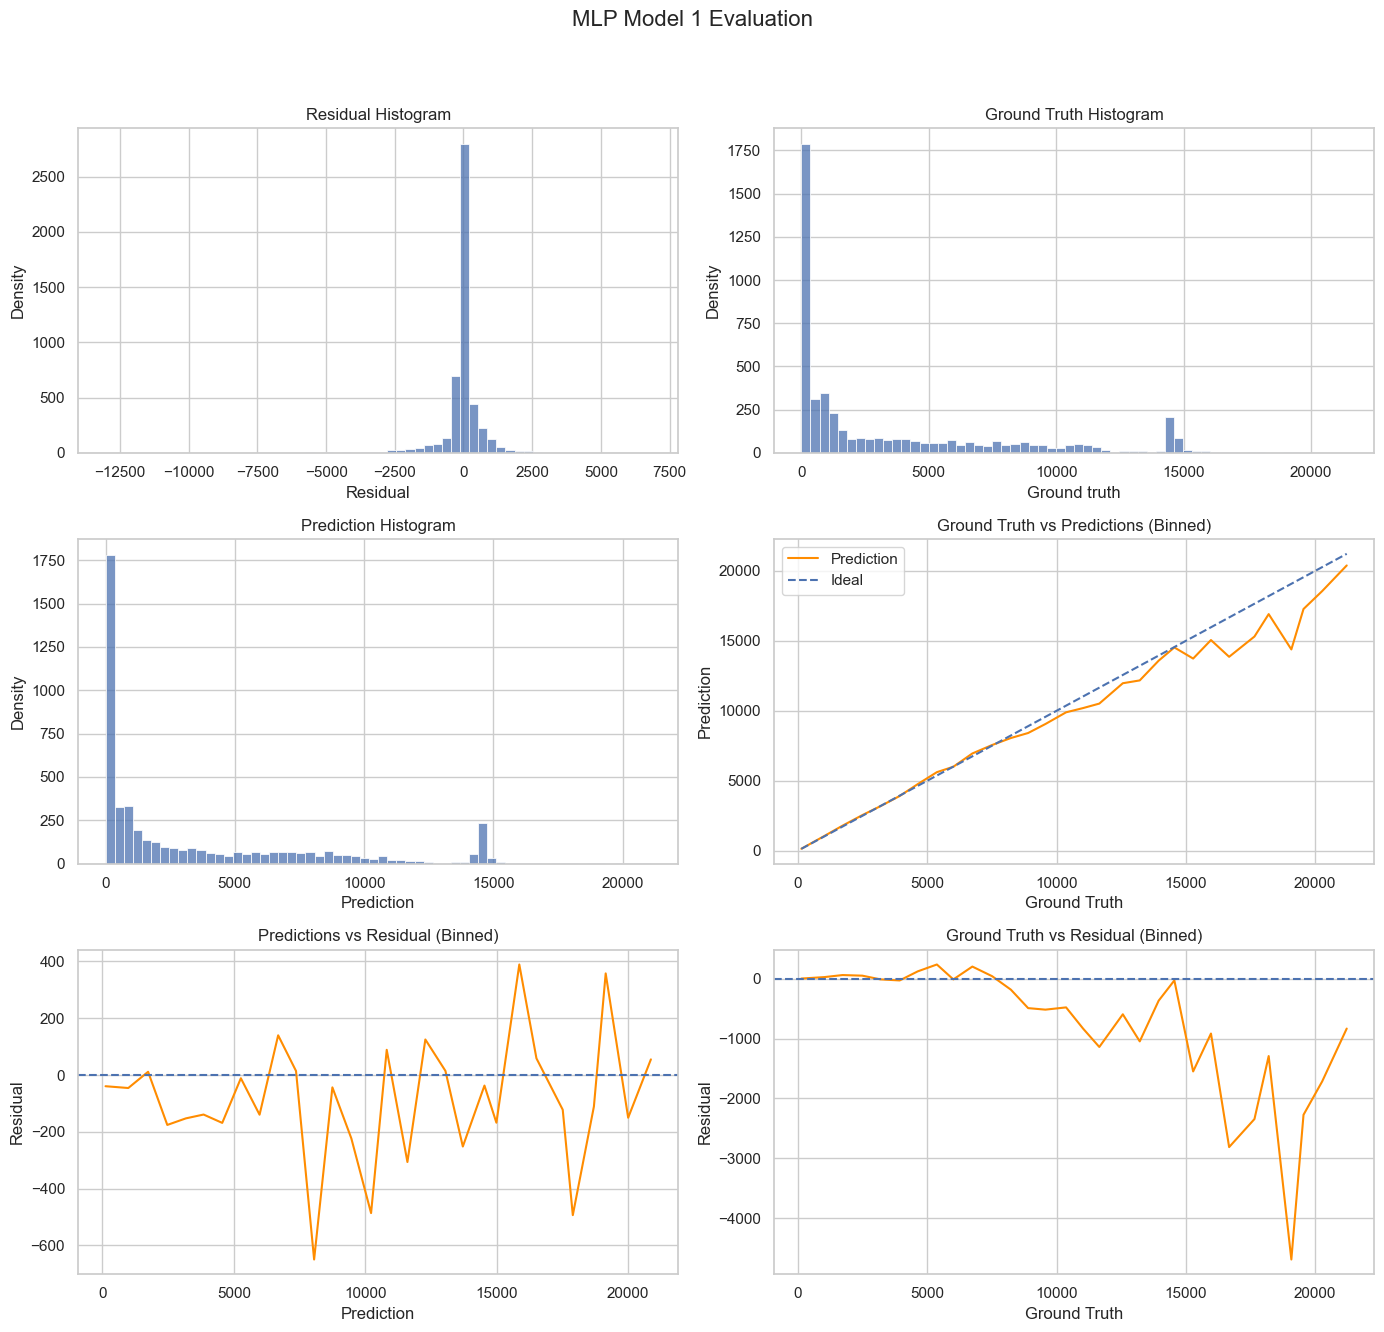

In [38]:
# plot model evaluation
y_pred1 = model1.predict(X_test)
plot_model_evaluation(y_test, y_pred1, title="MLP Model 1 Evaluation")

In [39]:
# save model
model1.save("../Models/MLP1.keras")